Loading I-JEPA...


preprocessor_config.json:   0%|          | 0.00/325 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/497 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 2.52GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/517 [00:00<?, ?it/s]


Encoding Phase 1...
  ✓ labrador: decay=0.87
  ✓ cat: decay=1.45
  ✓ person: decay=1.23
  ✓ horse: decay=1.10
  ✓ landscape: decay=0.66

Encoding Phase 2...
  ✓ bulldog: decay=0.66
  ✓ kitten: decay=0.56
  ✓ car: decay=1.37
  ✓ coffee: decay=1.10
  ✓ puppy: decay=1.21

  ORIGINAL (init=1.0)
  Memory       Type       α      Final   Status
  labrador     OLD     0.87   0.008117    ALIVE
  cat          OLD     1.45   0.009902    ALIVE
  person       OLD     1.23   0.008601    ALIVE
  horse        OLD     1.10   0.007450    ALIVE
  landscape    OLD     0.66   0.007336    ALIVE
  bulldog      NEW     0.66   0.037728    ALIVE
  kitten       NEW     0.56   0.046205    ALIVE
  car          NEW     1.37   0.011544    ALIVE
  coffee       NEW     1.10   0.016631    ALIVE
  puppy        NEW     1.21   0.016145    ALIVE

  Old surviving: 5/5
  New surviving: 5/5
  Old memory retention: 14.6%

  FIX 1: Init at mean
  Memory       Type       α      Final   Status
  labrador     OLD     0.87   0.012

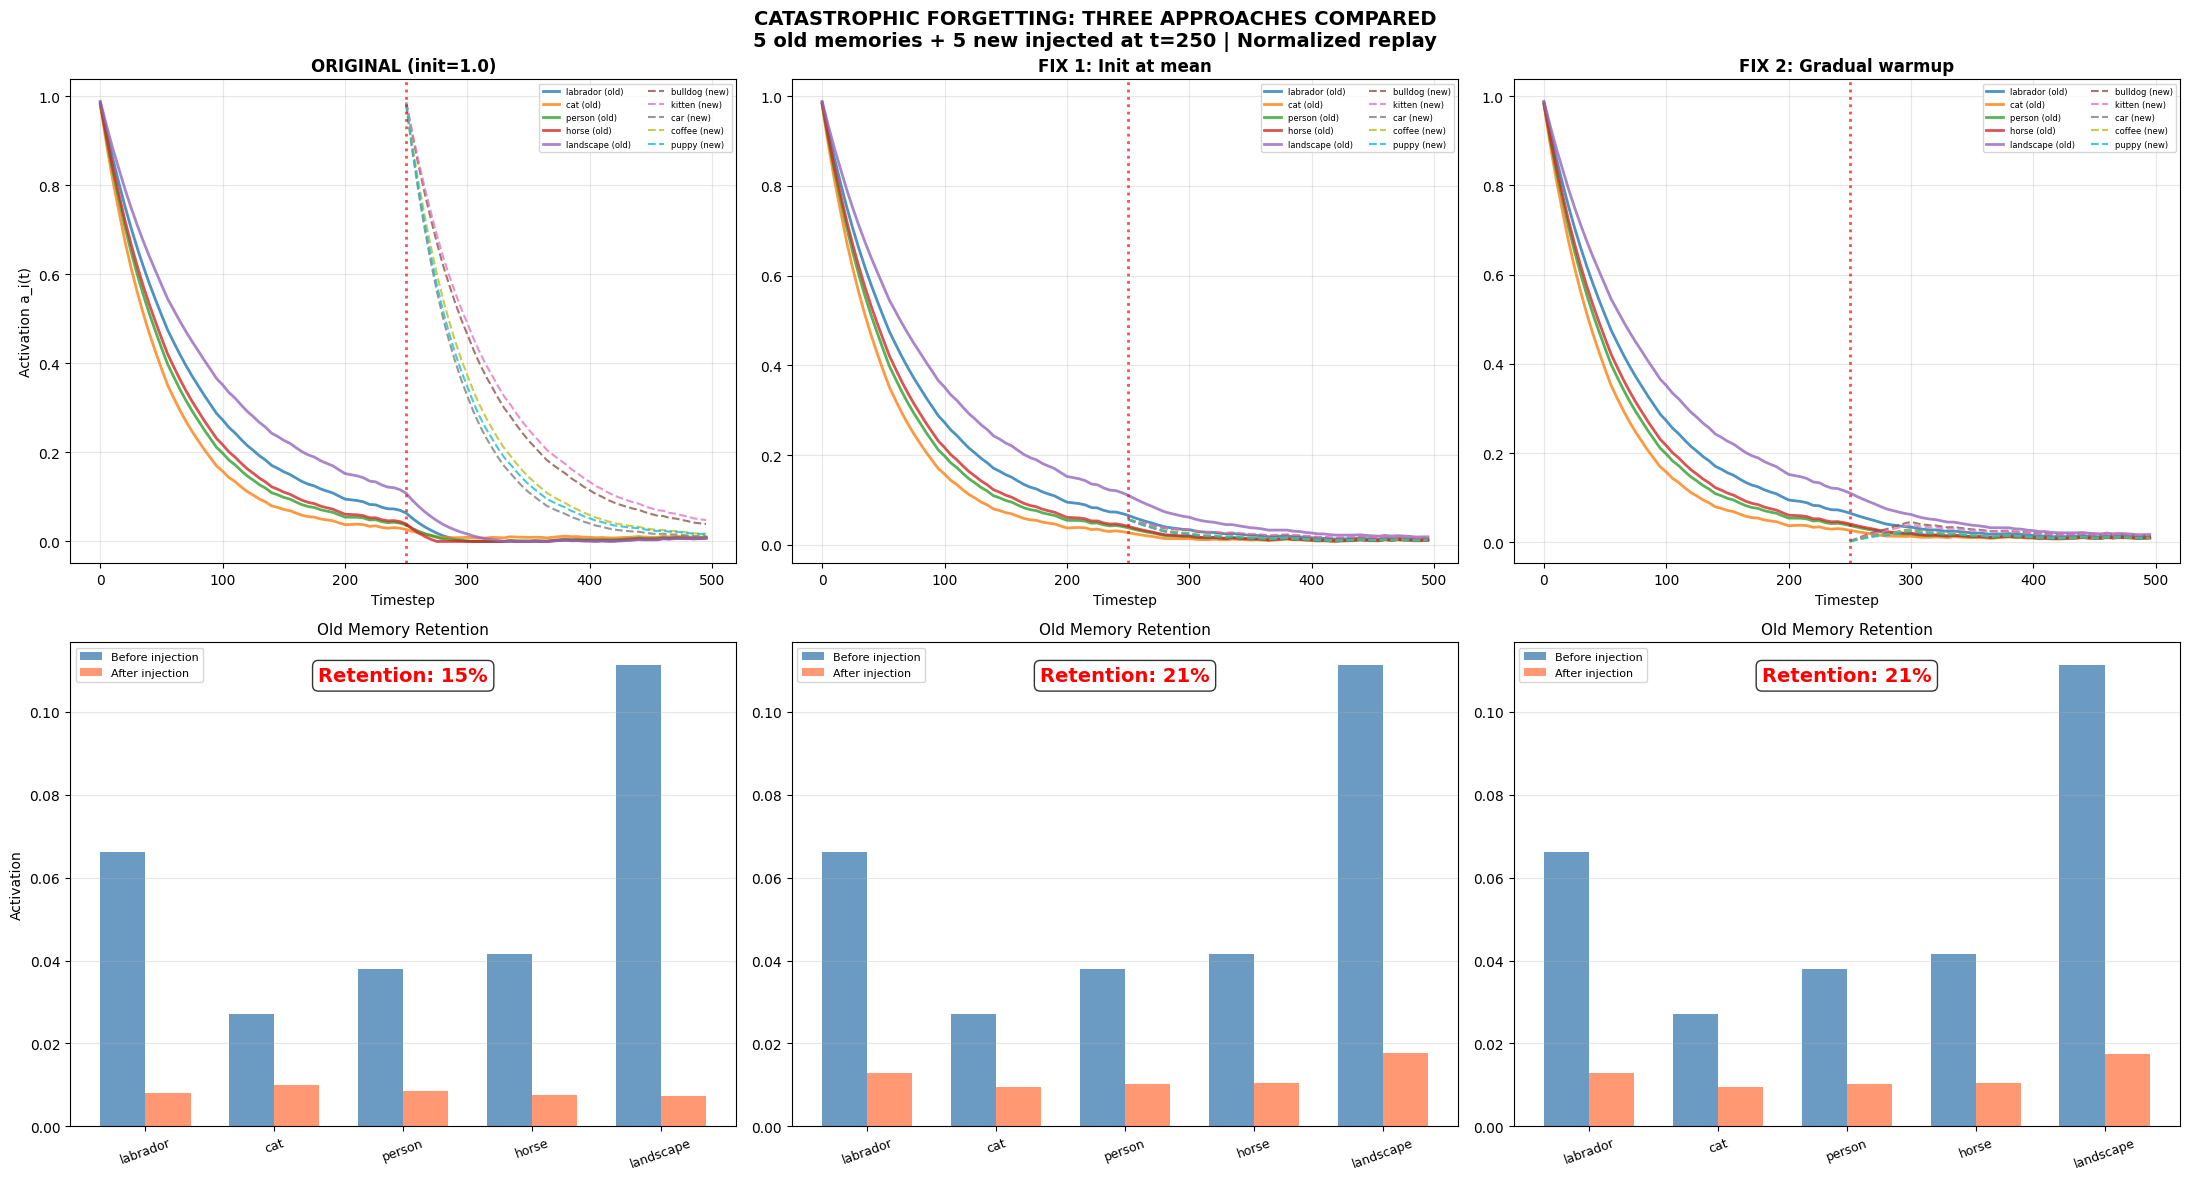


SUMMARY COMPARISON
Metric                             Original    Mean Init       Warmup
----------------------------------------------------------------------
  Old survivors                             5            5            5
  New survivors                             5            5            5
  Old retention %                       14.6%        21.3%        21.2%
  Max old activation                   0.0099       0.0176       0.0175
  Max new activation                   0.0462       0.0162       0.0166
  Old/New ratio                          0.32         0.98         0.96

BEST APPROACH:
  FIX 1: Init at mean — 21% old memory retention


In [1]:
# ============================================================
# CATASTROPHIC FORGETTING — THREE FIXES COMPARED
# Fix 1: Initialize new memories at mean activation (not 1.0)
# Fix 2: Initialize at mean + boost old replay temporarily
# Fix 3: Gradual warmup — new memories ramp up over 50 steps
# ============================================================

import torch
import torch.nn.functional as F
import numpy as np
from transformers import AutoProcessor, AutoModel
from PIL import Image
import requests
from io import BytesIO
import matplotlib.pyplot as plt

torch.manual_seed(42)
np.random.seed(42)

model_id = "facebook/ijepa_vith14_1k"
print("Loading I-JEPA...")
processor = AutoProcessor.from_pretrained(model_id)
encoder = AutoModel.from_pretrained(model_id).eval()

@torch.no_grad()
def encode_image(url):
    headers = {"User-Agent": "Mozilla/5.0"}
    response = requests.get(url, headers=headers, stream=True, timeout=15)
    response.raise_for_status()
    img = Image.open(BytesIO(response.content)).convert("RGB")
    inputs = processor(img, return_tensors="pt")
    outputs = encoder(**inputs)
    return outputs.last_hidden_state.mean(dim=1).squeeze()

# Same images as before
phase1_images = [
    ("https://images.unsplash.com/photo-1543466835-00a7907e9de1?w=400", "labrador"),
    ("https://images.unsplash.com/photo-1514888286974-6c03e2ca1dba?w=400", "cat"),
    ("https://images.unsplash.com/photo-1517841905240-472988babdf9?w=400", "person"),
    ("https://images.unsplash.com/photo-1560807707-8cc77767d783?w=400", "horse"),
    ("https://images.unsplash.com/photo-1506744038136-46273834b3fb?w=400", "landscape"),
]

phase2_images = [
    ("https://images.unsplash.com/photo-1583511655857-d19b40a7a54e?w=400", "bulldog"),
    ("https://images.unsplash.com/photo-1518791841217-8f162f1e1131?w=400", "kitten"),
    ("https://images.unsplash.com/photo-1494976388531-d1058494cdd8?w=400", "car"),
    ("https://images.unsplash.com/photo-1519125323398-675f0ddb6308?w=400", "coffee"),
    ("https://images.unsplash.com/photo-1574158622682-e40e69881006?w=400", "puppy"),
]

# ============================================================
# Memory system with configurable injection policy
# ============================================================
class ContinualMemory:
    def __init__(self, gamma=0.2, delta=0.1, beta=3.0, eta=0.8, h=0.01,
                 injection_mode="raw",        # "raw", "mean", "warmup"
                 warmup_steps=50):
        self.embeddings = []
        self.activations = torch.tensor([])
        self.gamma = gamma
        self.delta = delta
        self.beta = beta
        self.eta = eta
        self.h = h
        self.decay_rates = []
        self.labels = []
        self.injection_mode = injection_mode
        self.warmup_steps = warmup_steps
        # For warmup: track which memories are ramping up
        self.warmup_targets = {}  # index -> (target_activation, steps_remaining)

    def store(self, embedding, decay_rate, label, current_step=0):
        self.embeddings.append(embedding.clone())
        self.decay_rates.append(decay_rate)
        self.labels.append(label)
        idx = len(self.embeddings) - 1

        if len(self.activations) == 0:
            # First memory — always 1.0
            self.activations = torch.ones(1)
        elif current_step == 0:
            # Initial batch — all start at 1.0
            self.activations = torch.cat([self.activations, torch.ones(1)])
        else:
            # MID-SIMULATION INJECTION — apply policy
            if self.injection_mode == "raw":
                # Original: just slam in at 1.0
                init_val = 1.0
                self.activations = torch.cat([self.activations, torch.tensor([init_val])])

            elif self.injection_mode == "mean":
                # FIX 1: match current average
                init_val = self.activations.mean().item()
                self.activations = torch.cat([self.activations, torch.tensor([init_val])])

            elif self.injection_mode == "warmup":
                # FIX 2: start at 0, ramp up to mean over warmup_steps
                target = self.activations.mean().item()
                self.activations = torch.cat([self.activations, torch.tensor([0.001])])
                self.warmup_targets[idx] = (target, self.warmup_steps)

    def _build_laplacian(self):
        X = torch.stack(self.embeddings)
        X_norm = F.normalize(X, dim=1)
        W = torch.clamp(X_norm @ X_norm.T, min=0)
        W.fill_diagonal_(0)
        D = torch.diag(W.sum(dim=1))
        return D - W

    def _replay_operator(self):
        X = torch.stack(self.embeddings)
        X_norm = F.normalize(X, dim=1)
        s = X_norm @ (X_norm.T @ self.activations)
        return F.softmax(self.beta * s, dim=0)

    def step(self, replay_prob=0.3):
        if len(self.embeddings) < 2:
            return

        # Apply warmup ramps
        for idx in list(self.warmup_targets.keys()):
            target, remaining = self.warmup_targets[idx]
            if remaining > 0:
                # Linear ramp: add (target / warmup_steps) each step
                ramp = target / self.warmup_steps
                self.activations[idx] = self.activations[idx] + ramp
                self.warmup_targets[idx] = (target, remaining - 1)
            else:
                del self.warmup_targets[idx]

        a = self.activations
        N = len(a)

        A = torch.diag(torch.tensor(self.decay_rates, dtype=torch.float32))
        L = self._build_laplacian()

        f_decay = -A @ a
        f_diffusion = -self.gamma * L @ a
        f_inhibition = -self.delta * a.sum() * torch.ones(N)

        S = 1.0 if np.random.random() < replay_prob else 0.0
        Fa = self._replay_operator()
        f_replay = self.eta * S * Fa

        da_dt = f_decay + f_diffusion + f_inhibition + f_replay
        self.activations = a + self.h * da_dt
        self.activations = torch.clamp(self.activations, min=0)


# ============================================================
# Encode all images once
# ============================================================
print("\nEncoding Phase 1...")
phase1_data = []
for url, label in phase1_images:
    try:
        emb = encode_image(url)
    except:
        emb = torch.randn(1280)
        print(f"  ⚠️ {label}: fallback embedding")
    decay = np.random.uniform(0.5, 1.5)
    phase1_data.append((emb.clone(), decay, label))
    print(f"  ✓ {label}: decay={decay:.2f}")

print("\nEncoding Phase 2...")
phase2_data = []
for url, label in phase2_images:
    try:
        emb = encode_image(url)
    except:
        emb = torch.randn(1280)
        print(f"  ⚠️ {label}: fallback embedding")
    decay = np.random.uniform(0.5, 1.5)
    phase2_data.append((emb.clone(), decay, label))
    print(f"  ✓ {label}: decay={decay:.2f}")

# ============================================================
# Run THREE versions
# ============================================================
TOTAL_STEPS = 500
INJECT_AT = 250

configs = [
    ("raw", "ORIGINAL (init=1.0)"),
    ("mean", "FIX 1: Init at mean"),
    ("warmup", "FIX 2: Gradual warmup"),
]

all_results = {}

for mode, description in configs:
    torch.manual_seed(42)
    np.random.seed(42)

    mem = ContinualMemory(injection_mode=mode, warmup_steps=50)

    # Store Phase 1
    for emb, decay, label in phase1_data:
        mem.store(emb, decay, label, current_step=0)

    # Phase 1 history
    act_history = []
    for t in range(INJECT_AT):
        mem.step(replay_prob=0.3)
        if t % 5 == 0:
            # Pad to 10 with NaN for plotting
            acts = mem.activations.clone().numpy()
            padded = np.full(10, np.nan)
            padded[:len(acts)] = acts
            act_history.append((t, padded))

    pre_inject = mem.activations.clone().numpy()

    # Inject Phase 2
    for emb, decay, label in phase2_data:
        mem.store(emb, decay, label, current_step=INJECT_AT)

    # Phase 2 history
    for t in range(INJECT_AT, TOTAL_STEPS):
        mem.step(replay_prob=0.3)
        if t % 5 == 0:
            acts = mem.activations.clone().numpy()
            padded = np.full(10, np.nan)
            padded[:len(acts)] = acts
            act_history.append((t, padded))

    final = mem.activations.clone().numpy()
    all_labels = list(mem.labels)
    all_decays = list(mem.decay_rates)

    all_results[mode] = {
        'history': act_history,
        'pre_inject': pre_inject,
        'final': final,
        'labels': all_labels,
        'decays': all_decays,
    }

    print(f"\n{'='*60}")
    print(f"  {description}")
    print(f"{'='*60}")
    print(f"  {'Memory':<12} {'Type':<6} {'α':>5} {'Final':>10} {'Status':>8}")
    n_old = len(phase1_data)
    old_alive = 0
    new_alive = 0
    for i, l in enumerate(all_labels):
        is_old = i < n_old
        alive = final[i] > 0.001
        if alive and is_old: old_alive += 1
        if alive and not is_old: new_alive += 1
        print(f"  {l:<12} {'OLD' if is_old else 'NEW':<6} {all_decays[i]:>5.2f} {final[i]:>10.6f} {'ALIVE' if alive else 'DEAD':>8}")
    print(f"\n  Old surviving: {old_alive}/{n_old}")
    print(f"  New surviving: {new_alive}/{len(phase2_data)}")

    # Old memory retention
    total_old_before = pre_inject.sum()
    total_old_after = final[:n_old].sum()
    retention = (total_old_after / total_old_before) * 100
    print(f"  Old memory retention: {retention:.1f}%")

# ============================================================
# COMPARISON PLOTS
# ============================================================
fig, axes = plt.subplots(2, 3, figsize=(22, 12))

n_old = len(phase1_data)
n_new = len(phase2_data)

for col, (mode, description) in enumerate(configs):
    res = all_results[mode]
    steps = [h[0] for h in res['history']]
    acts_over_time = np.array([h[1] for h in res['history']])

    # Top row: Activation trajectories
    ax = axes[0][col]
    for i in range(10):
        is_old = i < n_old
        style = '-' if is_old else '--'
        lw = 2.0 if is_old else 1.5
        label_str = f"{res['labels'][i]} ({'old' if is_old else 'new'})"
        ax.plot(steps, acts_over_time[:, i], linestyle=style, linewidth=lw,
                label=label_str, alpha=0.8)
    ax.axvline(x=INJECT_AT, color='red', linestyle=':', linewidth=2, alpha=0.7)
    ax.set_title(description, fontsize=12, fontweight='bold')
    ax.set_xlabel("Timestep")
    if col == 0: ax.set_ylabel("Activation a_i(t)")
    ax.legend(fontsize=6, ncol=2, loc='upper right')
    ax.grid(True, alpha=0.3)

    # Bottom row: Before vs After for OLD memories
    ax = axes[1][col]
    x = np.arange(n_old)
    width = 0.35
    ax.bar(x - width/2, res['pre_inject'][:n_old], width,
           label='Before injection', color='steelblue', alpha=0.8)
    ax.bar(x + width/2, res['final'][:n_old], width,
           label='After injection', color='coral', alpha=0.8)
    ax.set_xticks(x)
    ax.set_xticklabels([res['labels'][i] for i in range(n_old)], rotation=20, fontsize=9)
    ax.set_title(f"Old Memory Retention", fontsize=11)
    if col == 0: ax.set_ylabel("Activation")
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3, axis='y')

    # Retention percentage annotation
    total_before = res['pre_inject'][:n_old].sum()
    total_after = res['final'][:n_old].sum()
    retention = (total_after / total_before) * 100
    ax.text(0.5, 0.95, f"Retention: {retention:.0f}%",
            transform=ax.transAxes, ha='center', va='top',
            fontsize=14, fontweight='bold',
            color='green' if retention > 50 else 'red',
            bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

fig.suptitle("CATASTROPHIC FORGETTING: THREE APPROACHES COMPARED\n"
             "5 old memories + 5 new injected at t=250 | Normalized replay",
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig("forgetting_fixes_comparison.png", dpi=150, bbox_inches='tight')
plt.show()

# ============================================================
# SUMMARY TABLE
# ============================================================
print(f"\n{'='*70}")
print("SUMMARY COMPARISON")
print(f"{'='*70}")
print(f"{'Metric':<30} {'Original':>12} {'Mean Init':>12} {'Warmup':>12}")
print("-" * 70)

for metric_name, metric_fn in [
    ("Old survivors", lambda r: sum(1 for x in r['final'][:n_old] if x > 0.001)),
    ("New survivors", lambda r: sum(1 for x in r['final'][n_old:] if x > 0.001)),
    ("Old retention %", lambda r: f"{(r['final'][:n_old].sum() / r['pre_inject'].sum()) * 100:.1f}%"),
    ("Max old activation", lambda r: f"{r['final'][:n_old].max():.4f}"),
    ("Max new activation", lambda r: f"{r['final'][n_old:].max():.4f}"),
    ("Old/New ratio", lambda r: f"{r['final'][:n_old].mean() / max(r['final'][n_old:].mean(), 1e-8):.2f}"),
]:
    vals = []
    for mode, _ in configs:
        vals.append(str(metric_fn(all_results[mode])))
    print(f"  {metric_name:<30} {vals[0]:>12} {vals[1]:>12} {vals[2]:>12}")

print(f"\n{'='*70}")
print("BEST APPROACH:")
retentions = {}
for mode, desc in configs:
    r = all_results[mode]
    retentions[mode] = (r['final'][:n_old].sum() / r['pre_inject'].sum()) * 100

best = max(retentions, key=retentions.get)
best_name = dict(configs)[best]
print(f"  {best_name} — {retentions[best]:.0f}% old memory retention")
print(f"{'='*70}")